# AgroSmart Puno · Big Data histórico (Open-Meteo, ~14 años por hora)

**Grupo 11 · Jose Armando Mamani Poccohuanca (humedad del suelo, Puno) · Mijael Yurins Coaquira Justo (temperatura, Azángaro)**

Este cuaderno amplía el volumen de datos con **datos reales**, no sintéticos: descarga el histórico horario de la
**Open-Meteo Historical Weather API** (reanálisis ERA5 / ERA5-Land) desde 2012 para las mismas dos zonas del proyecto
y lo procesa con **Spark** en arquitectura medallón (Bronze → Silver → Gold), igual que en la U1, pero con más de
100 000 filas por dimensión.

| | Humedad (José) | Temperatura (Mijael) |
|---|---|---|
| Zona | Puno (−15.84, −70.02) | Azángaro (−14.91, −70.19) |
| Variables | `soil_moisture_0_to_7cm`, `relative_humidity_2m` | `temperature_2m` |
| Periodo | 2012-01-01 → hace 7 días | 2012-01-01 → hace 7 días |

**Qué NO cambia:** los datos y modelos de la U1, la U2 y el flujo en tiempo real. Todo se guarda aparte en
`Historico_BigData/` y no escribe en PostgreSQL.

**Aclaración honesta:** el archivo histórico de Open-Meteo no ofrece la capa de suelo 0–1 cm que usa el tiempo real;
la capa más cercana es **0–7 cm**. Por eso el histórico de humedad se analiza como su propio conjunto de datos.

In [1]:
import os, sys, glob, time, json, math
SPARK_HOME = os.environ.get('SPARK_HOME', '/usr/local/spark')       # deja pyspark importable también al ejecutar con nbconvert
for ruta in [os.path.join(SPARK_HOME, 'python')] + glob.glob(os.path.join(SPARK_HOME, 'python', 'lib', 'py4j-*.zip')):
    if ruta not in sys.path: sys.path.insert(0, ruta)
from pathlib import Path
from datetime import date, timedelta
import requests, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F
from pyspark.sql.window import Window

RAIZ = Path('/home/jovyan/work/Historico_BigData')
BRONZE, GOLD, RES = RAIZ/'bronze', RAIZ/'gold', RAIZ/'resultados'
for p in (BRONZE, GOLD, RES): p.mkdir(parents=True, exist_ok=True)

INICIO = date(2012, 1, 1)
FIN = date.today() - timedelta(days=7)          # el archivo ERA5 se publica con unos días de retraso
DIMENSIONES = {
    'humedad':     {'lat': -15.84, 'lon': -70.02, 'zona': 'Puno',     'vars': ['soil_moisture_0_to_7cm', 'relative_humidity_2m']},
    'temperatura': {'lat': -14.91, 'lon': -70.19, 'zona': 'Azángaro', 'vars': ['temperature_2m']},
}

spark = (SparkSession.builder
    .appName('AgroSmart-Historico-BigData').master('local[*]')      # usa todos los núcleos de la laptop
    .config('spark.driver.memory', '4g')
    .config('spark.sql.shuffle.partitions', '16')
    .config('spark.sql.session.timeZone', 'America/Lima')
    .config('spark.ui.port', '4050')
    .getOrCreate())
spark.sparkContext.setLogLevel('WARN')
TIEMPOS = {}
print('Spark', spark.version, '| núcleos:', spark.sparkContext.defaultParallelism, '| periodo:', INICIO, '→', FIN)

Spark 3.5.0 | núcleos: 8 | periodo: 2012-01-01 → 2026-11-13


## 1. Bronze · descarga del histórico horario (un archivo CSV por año y dimensión)
La descarga es idempotente: si el archivo del año ya existe, no se vuelve a pedir.

In [2]:
URL = 'https://archive-api.open-meteo.com/v1/archive'

def descargar(dim, cfg, anio):
    destino = BRONZE/dim/f'anio={anio}.csv'
    if destino.exists():
        return destino, 'ya existía'
    ini = max(date(anio, 1, 1), INICIO); fin = min(date(anio, 12, 31), FIN)
    params = {'latitude': cfg['lat'], 'longitude': cfg['lon'], 'start_date': ini.isoformat(), 'end_date': fin.isoformat(),
              'hourly': ','.join(cfg['vars']), 'timezone': 'America/Lima'}
    ultimo = None
    for intento in range(5):
        try:
            r = requests.get(URL, params=params, timeout=60)
            if r.status_code == 429:
                time.sleep(20 * (intento + 1)); continue
            r.raise_for_status()
            h = r.json()['hourly']
            df = pd.DataFrame(h).rename(columns={'time': 'fecha'})
            df.insert(1, 'ubicacion', cfg['zona'])
            df['fuente'] = 'open_meteo_archive_era5'
            destino.parent.mkdir(parents=True, exist_ok=True)
            df.to_csv(destino, index=False)
            return destino, f'{len(df)} filas'
        except Exception as exc:
            ultimo = exc; time.sleep(5 * (intento + 1))
    raise RuntimeError(f'No se pudo descargar {dim} {anio}: {ultimo}')

t0 = time.time()
for dim, cfg in DIMENSIONES.items():
    for anio in range(INICIO.year, FIN.year + 1):
        ruta, estado = descargar(dim, cfg, anio)
        print(f'{dim:12s} {anio}  {estado}')
        time.sleep(0.5)
TIEMPOS['descarga_s'] = round(time.time() - t0, 1)
print('Descarga terminada en', TIEMPOS['descarga_s'], 's')

humedad      2012  ya existía
humedad      2013  ya existía
humedad      2014  ya existía
humedad      2015  ya existía
humedad      2016  ya existía
humedad      2017  ya existía
humedad      2018  ya existía
humedad      2019  ya existía
humedad      2020  ya existía
humedad      2021  ya existía
humedad      2022  ya existía
humedad      2023  ya existía
humedad      2024  ya existía
humedad      2025  ya existía
humedad      2026  ya existía
temperatura  2012  ya existía
temperatura  2013  ya existía
temperatura  2014  ya existía
temperatura  2015  ya existía
temperatura  2016  ya existía
temperatura  2017  ya existía
temperatura  2018  ya existía
temperatura  2019  ya existía
temperatura  2020  ya existía
temperatura  2021  ya existía
temperatura  2022  ya existía
temperatura  2023  ya existía
temperatura  2024  ya existía
temperatura  2025  ya existía
temperatura  2026  ya existía
Descarga terminada en 15.0 s


## 2. Silver · Spark lee el Bronze, tipa, valida rangos y elimina duplicados

In [3]:
t0 = time.time()
def leer_bronze(dim):
    return (spark.read.option('header', True).csv(str(BRONZE/dim/'*.csv'))
            .withColumn('fecha', F.to_timestamp('fecha', "yyyy-MM-dd'T'HH:mm")))

hum_b = leer_bronze('humedad')
hum = (hum_b.select('fecha', 'ubicacion', 'fuente',
         (F.col('soil_moisture_0_to_7cm').cast('double') * 100).alias('humedad_suelo_pct'),
         F.col('relative_humidity_2m').cast('double').alias('humedad_aire_pct')))
tem_b = leer_bronze('temperatura')
tem = tem_b.select('fecha', 'ubicacion', 'fuente', F.col('temperature_2m').cast('double').alias('temperatura_c'))

def calidad(df, col, lo, hi, nombre):
    total = df.count()
    nulos = df.filter(F.col(col).isNull()).count()
    fuera = df.filter(F.col(col).isNotNull() & ((F.col(col) < lo) | (F.col(col) > hi))).count()
    w = Window.partitionBy('fecha').orderBy(F.col(col).desc_nulls_last())
    limpio = (df.filter(F.col(col).isNotNull() & F.col(col).between(lo, hi))
                .withColumn('_r', F.row_number().over(w)).filter('_r = 1').drop('_r'))
    final = limpio.count()
    return limpio, {'dimension': nombre, 'bronze': total, 'nulos': nulos, 'fuera_de_rango': fuera,
                    'duplicados': total - nulos - fuera - final, 'silver': final}

hum_s, q_h = calidad(hum, 'humedad_suelo_pct', 0, 100, 'humedad')
tem_s, q_t = calidad(tem, 'temperatura_c', -40, 40, 'temperatura')
CALIDAD = pd.DataFrame([q_h, q_t])
TIEMPOS['silver_s'] = round(time.time() - t0, 1)
CALIDAD

,dimension,bronze,nulos,fuera_de_rango,duplicados,silver
0,humedad,130320,0,0,0,130320
1,temperatura,130320,0,0,0,130320


## 3. Gold · Parquet particionado por año y mes

In [4]:
t0 = time.time()
def a_gold(df, dim):
    salida = GOLD/dim
    (df.withColumn('anio', F.year('fecha')).withColumn('mes', F.month('fecha'))
       .repartition('anio').write.mode('overwrite').partitionBy('anio', 'mes').parquet(str(salida)))
    g = spark.read.parquet(str(salida))
    archivos = list(salida.rglob('*.parquet'))
    mb = sum(f.stat().st_size for f in archivos) / 1e6
    return g, {'dimension': dim, 'filas_gold': g.count(), 'archivos_parquet': len(archivos), 'tamano_mb': round(mb, 2),
               'desde': str(g.agg(F.min('fecha')).first()[0]), 'hasta': str(g.agg(F.max('fecha')).first()[0])}

hum_g, g_h = a_gold(hum_s, 'humedad')
tem_g, g_t = a_gold(tem_s, 'temperatura')
GOLD_INFO = pd.DataFrame([g_h, g_t])
TIEMPOS['gold_s'] = round(time.time() - t0, 1)
GOLD_INFO

,dimension,filas_gold,archivos_parquet,tamano_mb,desde,hasta
0,humedad,130320,179,1.45,2012-01-01 00:00:00,2026-11-12 23:00:00
1,temperatura,130320,179,1.22,2012-01-01 00:00:00,2026-11-12 23:00:00


## 4. Análisis con Spark sobre todo el histórico

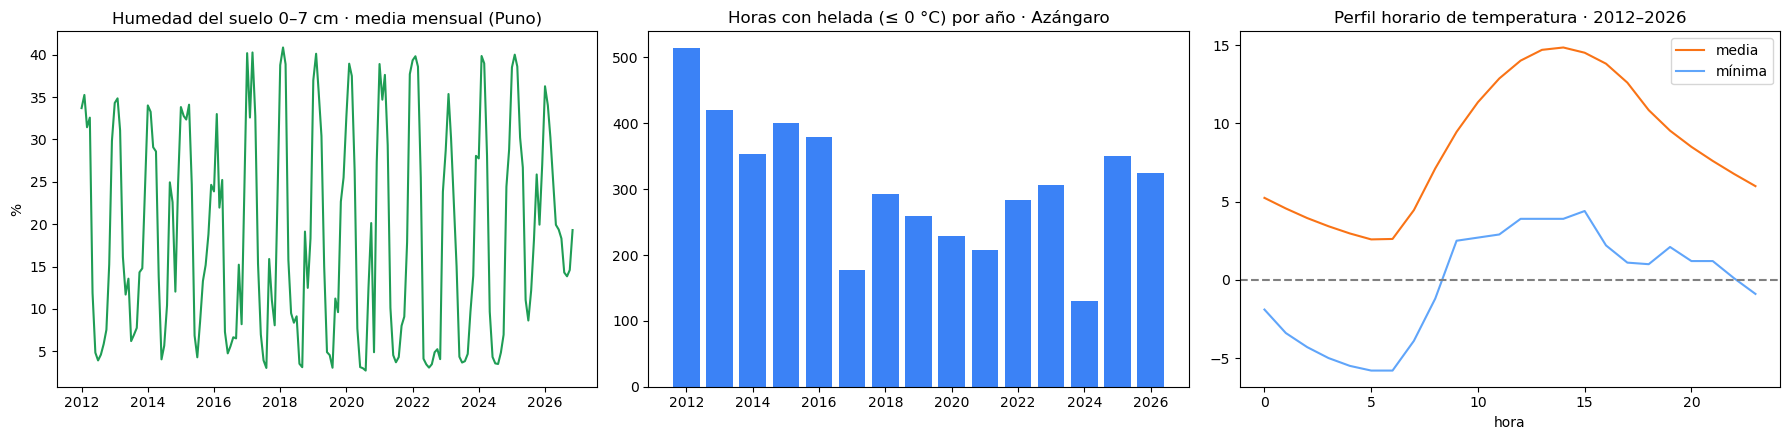

,anio,minima,media,horas_helada
0,2012,-5.8,8.00,514
1,2013,-4.4,8.09,420
2,2014,-4.3,8.16,354
3,2015,-5.8,8.14,401
4,2016,-4.7,8.72,379
5,2017,-3.3,8.68,177
6,2018,-3.1,8.32,292
7,2019,-3.6,8.59,259
8,2020,-4.5,8.98,229
9,2021,-3.4,8.56,207


In [5]:
mens_h = (hum_g.groupBy('anio', 'mes').agg(F.avg('humedad_suelo_pct').alias('suelo_media'),
           F.sum(F.when(F.col('humedad_suelo_pct') < 20, 1).otherwise(0)).alias('horas_bajo_20'))
           .orderBy('anio', 'mes').toPandas())
anual_t = (tem_g.groupBy('anio').agg(F.min('temperatura_c').alias('minima'), F.avg('temperatura_c').alias('media'),
           F.sum(F.when(F.col('temperatura_c') <= 0, 1).otherwise(0)).alias('horas_helada'))
           .orderBy('anio').toPandas())
perfil = (tem_g.groupBy(F.hour('fecha').alias('hora')).agg(F.avg('temperatura_c').alias('media'),
           F.min('temperatura_c').alias('minima')).orderBy('hora').toPandas())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
x = pd.to_datetime(mens_h['anio'].astype(str) + '-' + mens_h['mes'].astype(str) + '-01')
ax[0].plot(x, mens_h['suelo_media'], color='#1f9d55'); ax[0].set_title('Humedad del suelo 0–7 cm · media mensual (Puno)'); ax[0].set_ylabel('%')
ax[1].bar(anual_t['anio'], anual_t['horas_helada'], color='#3b82f6'); ax[1].set_title('Horas con helada (≤ 0 °C) por año · Azángaro')
ax[2].plot(perfil['hora'], perfil['media'], label='media', color='#f97316'); ax[2].plot(perfil['hora'], perfil['minima'], label='mínima', color='#60a5fa')
ax[2].axhline(0, ls='--', c='gray'); ax[2].set_title('Perfil horario de temperatura · 2012–2026'); ax[2].set_xlabel('hora'); ax[2].legend()
plt.tight_layout(); plt.savefig(RES/'historico_analisis.png', dpi=130); plt.show()
anual_t.round(2)

## 5. Modelo +1 h entrenado con el histórico completo (MLlib) frente a la persistencia
Partición cronológica: entrenamiento hasta 2022, validación 2023–2024 y prueba desde 2025.

In [6]:
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

def preparar(g, col, extra=()):
    w = Window.partitionBy('ubicacion').orderBy('fecha')
    df = g.select('fecha', 'ubicacion', col, *extra)
    for k in (1, 2, 3, 24):
        df = df.withColumn(f'lag{k}', F.lag(col, k).over(w))
    df = (df.withColumn('objetivo', F.lead(col, 1).over(w))
            .withColumn('h_sin', F.sin(2 * math.pi * F.hour('fecha') / 24)).withColumn('h_cos', F.cos(2 * math.pi * F.hour('fecha') / 24))
            .withColumn('m_sin', F.sin(2 * math.pi * F.month('fecha') / 12)).withColumn('m_cos', F.cos(2 * math.pi * F.month('fecha') / 12))
            .dropna())
    feats = [col, 'lag1', 'lag2', 'lag3', 'lag24', 'h_sin', 'h_cos', 'm_sin', 'm_cos', *extra]
    df = VectorAssembler(inputCols=feats, outputCol='features').transform(df)
    return (df.filter(F.year('fecha') <= 2022).cache(), df.filter(F.year('fecha').between(2023, 2024)).cache(),
            df.filter(F.year('fecha') >= 2025).cache())

ev = RegressionEvaluator(labelCol='objetivo', predictionCol='prediction', metricName='rmse')
def evaluar(nombre, g, col, extra=()):
    tr, va, te = preparar(g, col, extra)
    filas = []
    pers = te.withColumn('prediction', F.col(col))
    rm_p = ev.evaluate(pers)
    filas.append({'dimension': nombre, 'modelo': 'Persistencia (último valor)', 'rmse_prueba': rm_p})
    for mname, est in [('Regresión lineal', LinearRegression(labelCol='objetivo', regParam=0.01)),
                       ('Gradient Boosted Trees', GBTRegressor(labelCol='objetivo', maxIter=40, maxDepth=6, seed=42))]:
        t0 = time.time(); m = est.fit(tr)
        filas.append({'dimension': nombre, 'modelo': mname, 'rmse_validacion': ev.evaluate(m.transform(va)),
                      'rmse_prueba': ev.evaluate(m.transform(te)), 'entrenamiento_s': round(time.time() - t0, 1)})
    out = pd.DataFrame(filas)
    out['mejora_vs_persistencia_%'] = (1 - out['rmse_prueba'] / rm_p) * 100
    out['filas_entrenamiento'] = tr.count(); out['filas_prueba'] = te.count()
    return out

t0 = time.time()
MODELOS = pd.concat([evaluar('humedad', hum_g, 'humedad_suelo_pct', ('humedad_aire_pct',)),
                     evaluar('temperatura', tem_g, 'temperatura_c')], ignore_index=True)
TIEMPOS['modelos_s'] = round(time.time() - t0, 1)
MODELOS.round(4)

,dimension,modelo,rmse_prueba,rmse_validacion,entrenamiento_s,mejora_vs_persistencia_%,filas_entrenamiento,filas_prueba
0,humedad,Persistencia (último valor),0.6948,NaN,NaN,0.0000,96408,16343
1,humedad,Regresión lineal,0.7187,0.6460,11.2,-3.4304,96408,16343
2,humedad,Gradient Boosted Trees,0.9179,0.7384,26.7,-32.1023,96408,16343
3,temperatura,Persistencia (último valor),1.6356,NaN,NaN,0.0000,96408,16343
4,temperatura,Regresión lineal,1.0025,1.0111,9.1,38.7106,96408,16343
5,temperatura,Gradient Boosted Trees,0.8794,0.8758,26.0,46.2350,96408,16343


## 6. Resumen y manifiesto

In [7]:
resumen = {
    'generado': pd.Timestamp.now(tz='America/Lima').isoformat(),
    'fuente': 'Open-Meteo Historical Weather API (ERA5 / ERA5-Land) · archive-api.open-meteo.com',
    'periodo': [INICIO.isoformat(), FIN.isoformat()],
    'spark_nucleos': spark.sparkContext.defaultParallelism,
    'calidad': CALIDAD.to_dict('records'), 'gold': GOLD_INFO.to_dict('records'),
    'modelos': MODELOS.round(4).to_dict('records'), 'tiempos_s': TIEMPOS,
}
(RES/'resumen_historico.json').write_text(json.dumps(resumen, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
total = int(GOLD_INFO['filas_gold'].sum())
print(f"Filas Gold · humedad: {g_h['filas_gold']:,} | temperatura: {g_t['filas_gold']:,} | total: {total:,}".replace(',', ' '))
print('Tiempos (s):', TIEMPOS)
print('Manifiesto:', RES/'resumen_historico.json')

Filas Gold · humedad: 130 320 | temperatura: 130 320 | total: 260 640
Tiempos (s): {'descarga_s': 15.0, 'silver_s': 16.7, 'gold_s': 88.0, 'modelos_s': 85.4}
Manifiesto: /home/jovyan/work/Historico_BigData/resultados/resumen_historico.json
